## Почему одного power недостаточно: Type S и Type M ошибки в A/B-тестах

В классическом подходе к планированию эксперимента обычно обсуждают ошибки I и II рода, уровень значимости $\alpha$, мощность теста $1-\beta$ и MDE.  
Этого достаточно, чтобы ответить на вопрос: **"с какой вероятностью мы обнаружим эффект заданного размера?"**.

Но для практики A/B-тестов этого часто недостаточно.

Даже если результат оказался статистически значимым, остаются два важных вопроса:

1. **Не перепутали ли мы направление эффекта?**  
   Например, решили, что новая фича улучшает метрику, хотя в реальности она её ухудшает.

2. **Не завышаем ли мы размер эффекта?**  
   Например, увидели uplift $+1.2\text{ п.п.}$, а реальный эффект ближе к $+0.3\text{ п.п.}$.

Именно для ответа на эти вопросы [Andrew Gelman и John Carlin](https://errorstatistics.com/wp-content/uploads/2019/01/gelman-carlin.pdf) предложили смотреть не только на уже упомянутые пораметры, но и на:

- **`Type S error (Sign)`** — вероятность ошибиться в знаке эффекта;
- **`Type M error (Magnitude)`** — насколько условно значимый результат в среднем завышает истинный эффект.

### Главный тезис

> **Проблема низкой мощности состоит не только в том, что мы можем не заметить реальный эффект. Проблема ещё и в том, что среди “победивших” значимых результатов будут непропорционально часто встречаться слишком большие и иногда даже неверные по знаку оценки.**

Поэтому хороший анализ A/B-теста должен отвечать не только на вопрос *“обнаружим ли мы эффект?”*,  
но и на вопросы *“насколько можно доверять знаку эффекта?”* и *“насколько сильно значимый результат может преувеличивать реальный uplift?”*.




### Почему эта проблема реально важна

Интерес к Type S и Type M ошибкам возник не на пустом месте. В психологии, медицине и других прикладных областях накопилось много исследований, где были получены статистически значимые результаты, но затем они плохо воспроизводились в повторных экспериментах. Например, в известном Reproducibility Project по психологии было воспроизведено 100 исследований: в оригинальных работах статистически значимые результаты наблюдались почти всегда, а в репликациях — лишь примерно в трети случаев. Это не означает, что все исходные результаты были “ложными”, но показывает важную проблему: **сам факт статистической значимости ещё не гарантирует, что оценка эффекта надёжна по знаку и масштабу**.

Даже если эффект оказался “значимым”, он может:

- иметь неверный знак;
- быть сильно завышен по модулю;
- не воспроизвестись в следующем эксперименте.

Именно поэтому в современном анализе экспериментов всё чаще обсуждают не только пощность у уровень значимости, но и качество интерпретации значимых результатов.

## 1. Классическая постановка A/B-теста

Пусть мы сравниваем контрольную и тестовую версии продукта. Обозначим истинный эффект через $\theta$.

Например:

- $\theta > 0$ — тест улучшает метрику
- $\theta = 0$ — эффекта нет
- $\theta < 0$ — тест ухудшает метрику

Обычно проверяется гипотеза:

$$
H_0:\theta = 0
\qquad \text{против} \qquad
H_1:\theta \neq 0
$$

* **Ошибка I рода**

  Ошибка I рода возникает, когда мы отвергаем $H_0$, хотя на самом деле эффекта нет. На практике это **ложноположительный результат**: решили, что фича работает, хотя реального эффекта нет.

$$
\alpha = P(\text{reject } H_0 \mid H_0 \text{ true})
$$

* **Ошибка II рода**

  Ошибка II рода возникает, когда мы не отвергаем $H_0$, хотя реальный эффект есть.На практике это **ложноотрицательный результат**: мы пропустили реально полезную фичу.

  $$
  \beta = P(\text{do not reject } H_0 \mid H_1 \text{ true})
  $$

* **Мощность теста**

  Мощность — это вероятность обнаружить эффект, если он действительно существует. Чем выше мощность, тем меньше риск пропустить реальный эффект.

$$
1 - \beta = P(\text{reject } H_0 \mid H_1 \text{ true})
$$



**Анализ мощности (power analysis)** несомненно полезен, но не достаточен. Он отвечает на вопрос:

> “С какой вероятностью эксперимент вообще обнаружит эффект?”

Но мощность **не отвечает** на два практических вопроса:

1. Если результат стал значимым, **верно ли определено направление эффекта**?
2. Если результат стал значимым, **насколько оценка эффекта близка к истинной**, а не просто случайно оказалась экстремальной?

Именно здесь появляются ошибки **Type S** и **Type M**.

## 2. Type S и Type M ошибки

Пусть $\hat{\theta}$ — оценка эффекта по данным, а $\theta$ — истинный эффект. Также пусть результат считается статистически значимым по некоторому правилу, например:

$$
|Z| > z_{1-\alpha/2}
$$

### 2.1. Type S error (Sign)

**Type S error** — это вероятность того, что при статистически значимом результате знак оценённого эффекта окажется неверным.

$$
\text{Type S} =
P\bigl(\operatorname{sign}(\hat{\theta}) \neq \operatorname{sign}(\theta)\mid \text{significant}\bigr)
$$

\
Представим, что истинный эффект на самом деле равен $\theta = +0.2 \text{ п.п.}$ То есть новая фича в среднем немного **улучшает** метрику. Но в одном конкретном шумном эксперименте мы получили статистически значимую оценку $\hat{\theta} = -0.4 \text{ п.п.}$. Тогда команда делает вывод, что фича **вредит**, и решает её отключить или не раскатывать, хотя в реальности ситуация **обратная** - фича не ухудшает метрику, а улучшает ее.

То есть ошибка здесь не просто в том, что мы неточно оценили величину эффекта. Мы сделали более серьёзную ошибку: **перепутали само направление воздействия**.

### 2.2. Type M error (Magnitude)

**Type M error** — это ожидаемое завышение величины эффекта среди статистически значимых результатов.

Чаще всего её записывают через exaggeration ratio:

$$
\text{Type M} =
\frac{
E\bigl(|\hat{\theta}| \mid \text{significant}\bigr)
}{
|\theta|
}
$$

\
Если истинный эффект: $\theta = 0.2$, а среди значимых результатов средняя оценка оказывается около: $E(|\hat{\theta}| \mid \text{significant}) = 0.6$, то

$$
\text{Type M} = \frac{0.6}{0.2} = 3
$$

Это значит, что **значимые результаты в среднем преувеличивают истинный эффект в 3 раза**.

### 2.3. Почему эти ошибки особенно важны в A/B-тестах

В продуктовой аналитике ошибку II рода обычно понимают хорошо: “жаль, мы не увидели полезный эффект”. Но на практике не менее опасны ситуации, где одновременно выполняются такие условия:

- тест слабый или маломощный
- уровень шума в метрике высокий
- реальный эффект маленький по сравнению с дисперсией данных

Если эти условия выполняются, то дальше возникает уже следствие:

> статистически значимыми чаще оказываются те реализации эксперимента, где наблюдённый эффект случайно получился особенно большим по модулю.

Именно это и создаёт проблемы Type M и Type S.

Тогда команда может раскатить фичу на всех пользователей, закладывая в бизнес-оценку слишком большой uplift и
- ожидать эффект, который потом не воспроизводится
- в совсем плохом сценарии даже принять решение в неправильную сторону

Именно поэтому Type M и Type S особенно важны для интерпретации A/B-тестов с маленькими эффектами и шумными метриками.

## 3. Почему одного Power Analysis недостаточно. Design Analysis

### Power Analysis и Design Analysis

Обычный Power Analysis устроен так:

1. мы задаём $\alpha$
2. фиксируем желаемую мощность, например $80\%$
3. задаём минимальный интересующий эффект (MDE)
4. считаем нужный размер выборки

Это полезно, но при такой логике фокус делается почти исключительно на вопросе **“получим ли мы значимость?”**

Gelman и Carlin показывают, что в шумных и маломощных исследованиях этого недостаточно, потому что **значимый результат сам по себе может вводить в заблуждение**.

Вместо узкого фокуса на мощности предлагается более широкая рамка — **Design Analysis**.

Идея такая:

- задать правдоподобный **истинный эффект** $\theta^{1}$
- задать стандартную ошибку $SE$ для оценки эффекта
- рассмотреть, какие результаты будет давать гипотетическое повторение такого эксперимента много раз

После этого оценивать не только мощность, но и:

- **Мощность** — как часто результат станет значимым
- **Type S** — как часто среди значимых результатов знак будет ошибочным
- **Type M** — насколько сильно значимые результаты будут завышать эффект

### 3.2. Почему нужен правдоподобный эффект, а не просто наблюдённый

Очень важный момент: нельзя механически брать **наблюдённую оценку эффекта из текущего эксперимента** и подставлять её как “истинный эффект” в post-hoc power analysis.

Это плохо, потому что если результат уже прошёл фильтр значимости, то наблюдённый эффект часто **смещён вверх по модулю**. То есть мы используем уже “отобранное удачное наблюдение”, а не реалистичную величину эффекта.

Например, команда провела тест и получила наблюдённый uplift $\hat{\theta} = 1.2 \text{ п.п.}$

После этого она подставляет эти же $1.2$ п.п. в формулу мощности и получает, например, мощность в 95%. На первый взгляд кажется, что эксперимент был очень качественным и надёжным.

Но здесь возникает логическая ошибка:

> Результат уже оказался значимым -> он мог попасть в выборку именно потому, что случайно оказался большим. Следовательно, подставлять его назад в расчёт мощности нельзя, потому что это уже **эффект после фильтра значимости**, а не независимая реалистичная оценка истинного сигнала.


Gelman позже отдельно разбирает именно эту проблему в своём блог-посте 2016 года, поясняя, что плохой post-hoc power analysis с подстановкой point estimate из данных может приводить к ложной уверенности и завышенной оценке качества исследования.

Поэтому для design analysis лучше опираться на:

- внешние исследования
- историю похожих экспериментов
- доменную экспертизу
- разумные диапазоны правдоподобных эффектов

## 4. Симуляции

### Вспомогательные функции

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# =========================
# общие функции и конфиг
# =========================

BASE_CONFIG = {
    "p_control": 0.10,
    "p_test_main": 0.102,          # истинный uplift = +0.2 п.п.
    "alpha": 0.05,
    "n_sim_main": 20000,
    "n_sim_hist": 50000,
    "base_seed": 42,
    "min_significant_for_stable_m": 100
}


def format_n_ru(n):
    """
    Форматирование числа с пробелом как разделителем тысяч чисто для красоты и читабельности
    """
    return f"{int(n):_}".replace("_", " ")


def two_proportion_z_test_from_counts(x_c, n_c, x_t, n_t):
    """
    Двусторонний z-test для сравнения двух долей.

    Параметры:
    x_c, x_t : массивы или числа
        Число успехов в control и test
    n_c, n_t : int
        Размеры групп

    Возвращает:
    effect_hat : оценка эффекта p_t - p_c
    z_stat     : z-статистика
    p_value    : двусторонний p-value
    """
    p_c_hat = x_c / n_c
    p_t_hat = x_t / n_t
    effect_hat = p_t_hat - p_c_hat

    # pooled estimate под H0
    p_pool = (x_c + x_t) / (n_c + n_t)
    se0 = np.sqrt(p_pool * (1 - p_pool) * (1 / n_c + 1 / n_t))

    # защита от деления на 0 в крайне редких случаях
    se0 = np.where(se0 == 0, np.nan, se0)

    z_stat = effect_hat / se0
    p_value = 2 * (1 - norm.cdf(np.abs(z_stat)))

    return effect_hat, z_stat, p_value


def simulate_ab_binary(
    p_control,
    p_test,
    n_per_group,
    n_sim=20000,
    alpha=0.05,
    seed=42,
    min_significant_for_stable_m=100
):
    """
    Симуляция A/B-теста для бинарной метрики.

    min_significant_for_stable_m:
        Порог, ниже которого оценку Type M считаем нестабильной,
        потому что она посчитана по слишком малому числу значимых результатов.
    """
    rng = np.random.default_rng(seed)

    x_c = rng.binomial(n=n_per_group, p=p_control, size=n_sim)
    x_t = rng.binomial(n=n_per_group, p=p_test, size=n_sim)

    effect_hat, z_stat, p_value = two_proportion_z_test_from_counts(
        x_c=x_c,
        n_c=n_per_group,
        x_t=x_t,
        n_t=n_per_group
    )

    significant = p_value < alpha
    significant_count = int(significant.sum())
    true_effect = p_test - p_control
    power = np.mean(significant)

    if np.isclose(true_effect, 0):
        type_s = np.nan
        type_m = np.nan
    else:
        if significant_count == 0:
            type_s = np.nan
            type_m = np.nan
        else:
            wrong_sign = np.sign(effect_hat[significant]) != np.sign(true_effect)
            type_s = np.mean(wrong_sign)
            type_m = np.mean(np.abs(effect_hat[significant])) / np.abs(true_effect)

    type_m_stable = significant_count >= min_significant_for_stable_m

    return {
        "true_effect": true_effect,
        "effect_hat": effect_hat,
        "z_stat": z_stat,
        "p_value": p_value,
        "significant": significant,
        "power": power,
        "type_s": type_s,
        "type_m": type_m,
        "significant_count": significant_count,
        "type_m_stable": type_m_stable
    }


def summarize_one_simulation(sim_result):
    """
    Короткая табличка по одной симуляции.
    """
    df = pd.DataFrame({
        "metric": [
            "True effect",
            "Power",
            "Type S",
            "Type M",
            "Significant results count",
            "Type M stable?"
        ],
        "value": [
            sim_result["true_effect"],
            sim_result["power"],
            sim_result["type_s"],
            sim_result["type_m"],
            sim_result["significant_count"],
            sim_result["type_m_stable"]
        ]
    })
    return df

### Симуляция №1: как размер выборки влияет на Power, Type S и Type M


Первая симуляция должна ответить на самый практический вопрос:

> Что произойдёт с качеством выводов, если мы будем увеличивать размер выборки?


Рассмотрим A/B-тест бинарной метрики, например конверсии.

Пусть:

- конверсия в контроле: $p_C = 0.10  $
- конверсия в тесте: $p_T = 0.102$

Тогда истинный эффект равен: $\theta = p_T - p_C = 0.002$, то есть uplift составляет **+0.2 п.п.**.

Теперь будем менять размер выборки на группу $n \in [2.000, 5.000, 10.000, 20.000, 50.000, 100 000,  250.000, 500.000, 750.000, 1.000.000]$


Для каждого значения $n$:

1. много раз генерируем контроль и тест
2. считаем наблюдённый эффект $\hat{\theta}$
3. строим статистику и $p$-value
4. отмечаем, стал ли результат значимым
5. среди значимых результатов считаем:
   - долю неверных знаков (Type S),
   - среднее завышение эффекта (Type M),
   - долю значимых результатов (Power)

---

Ожидаемая картина:

- **Power** будет расти с увеличением $n$
- **Type M** будет снижаться и стремиться к 1
- **Type S** тоже будет снижаться, но обычно заметно проявляется только в очень слабых дизайнах

Именно это и важно показать: **маленькая выборка опасна не только тем, что тест “ничего не найдёт”, но и тем, что редкие значимые результаты будут слишком экстремальными.**

In [11]:
# =========================
# симуляция №1
# =========================

p_control = BASE_CONFIG["p_control"]
p_test = BASE_CONFIG["p_test_main"]
alpha = BASE_CONFIG["alpha"]
n_sim = BASE_CONFIG["n_sim_main"]

sample_sizes = [2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 250_000, 500_000, 750_000, 1_000_000]

results_sim1 = []

for idx, n in enumerate(sample_sizes):
    sim = simulate_ab_binary(
        p_control=p_control,
        p_test=p_test,
        n_per_group=n,
        n_sim=n_sim,
        alpha=alpha,
        seed=BASE_CONFIG["base_seed"] + 1000 + idx,
        min_significant_for_stable_m=BASE_CONFIG["min_significant_for_stable_m"]
    )

    results_sim1.append({
        "n_per_group": n,
        "true_effect": sim["true_effect"],
        "power": sim["power"],
        "type_s": sim["type_s"],
        "type_m": sim["type_m"],
        "significant_count": sim["significant_count"],
        "type_m_stable": sim["type_m_stable"],
        "note": "" if sim["type_m_stable"] else "Осторожно: мало значимых результатов, Type M шумная"
    })

df_sim1 = pd.DataFrame(results_sim1)
df_sim1

,n_per_group,true_effect,power,type_s,type_m,significant_count,type_m_stable,note
0,2000,0.002,0.05365,0.263747,11.125815,1073,True,
1,5000,0.002,0.06270,0.177033,7.129585,1254,True,
2,10000,0.002,0.07355,0.097893,5.081169,1471,True,
3,20000,0.002,0.10280,0.043774,3.654171,2056,True,
4,50000,0.002,0.18515,0.005401,2.380248,3703,True,
5,100000,0.002,0.32455,0.001232,1.753164,6491,True,
6,250000,0.002,0.64735,0.000000,1.243345,12947,True,
7,500000,0.002,0.91475,0.000000,1.050713,18295,True,
8,750000,0.002,0.98240,0.000000,1.010928,19648,True,
9,1000000,0.002,0.99625,0.000000,1.003443,19925,True,


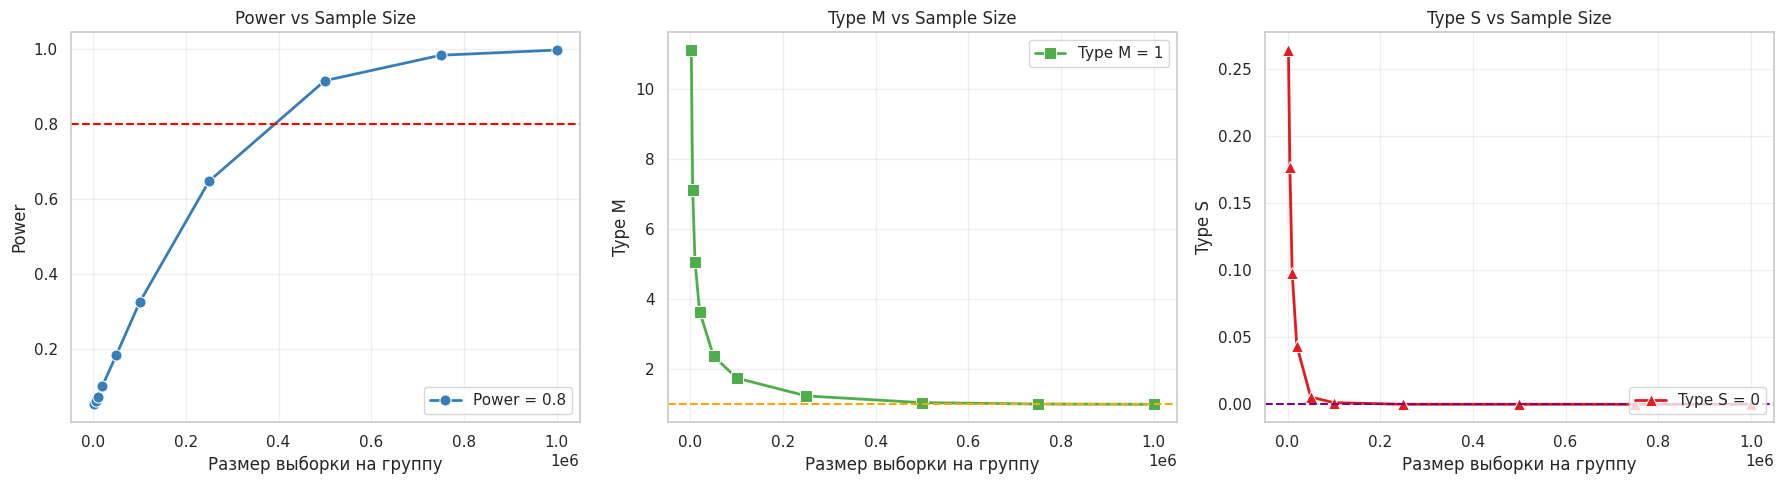

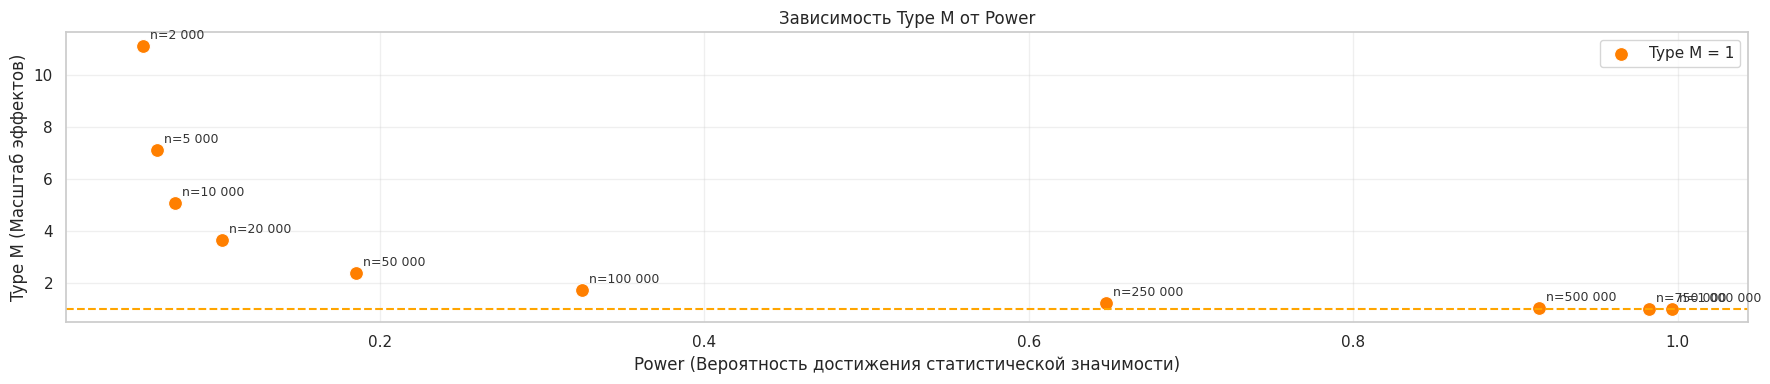

In [12]:
# Устанавливаем стиль и палитру
sns.set_theme(style="whitegrid", palette="colorblind")

# Общая ширина для обеих фигур
fig_width = 18

# --- Верхняя строка из 3 графиков ---
fig_top, axes = plt.subplots(1, 3, figsize=(fig_width, 5), sharex=True)

# График Power
sns.lineplot(
    x=df_sim1["n_per_group"],
    y=df_sim1["power"],
    marker="o",
    color="#377eb8",
    linewidth=2,
    markersize=8,
    ax=axes[0]
)
axes[0].axhline(0.8, linestyle="--", color="red")
axes[0].set_title("Power vs Sample Size")
axes[0].set_xlabel("Размер выборки на группу")
axes[0].set_ylabel("Power")
axes[0].legend(["Power = 0.8"], loc='lower right')
axes[0].grid(alpha=0.3)

# График Type M
sns.lineplot(
    x=df_sim1["n_per_group"],
    y=df_sim1["type_m"],
    marker="s",
    color="#4daf4a",
    linewidth=2,
    markersize=8,
    ax=axes[1]
)
axes[1].axhline(1.0, linestyle="--", color="orange")
axes[1].set_title("Type M vs Sample Size")
axes[1].set_xlabel("Размер выборки на группу")
axes[1].set_ylabel("Type M")
axes[1].legend(["Type M = 1"], loc='upper right')
axes[1].grid(alpha=0.3)

# График Type S
sns.lineplot(
    x=df_sim1["n_per_group"],
    y=df_sim1["type_s"],
    marker="^",
    color="#e41a1c",
    linewidth=2,
    markersize=8,
    ax=axes[2]
)
axes[2].axhline(0.0, linestyle="--", color="purple")
axes[2].set_title("Type S vs Sample Size")
axes[2].set_xlabel("Размер выборки на группу")
axes[2].set_ylabel("Type S")
axes[2].legend(["Type S = 0"], loc='lower right')
axes[2].grid(alpha=0.3)

plt.tight_layout()

# --- Нижний график (по ширине совпадает с верхней) ---
fig_bottom = plt.figure(figsize=(fig_width, 4))
ax = fig_bottom.add_subplot(111)

sns.scatterplot(
    x=df_sim1["power"],
    y=df_sim1["type_m"],
    s=100,
    color="#ff7f00",
    ax=ax
)

for _, row in df_sim1.iterrows():
    ax.annotate(
        f"n={format_n_ru(row['n_per_group'])}",
        (row["power"], row["type_m"]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=9,
        color="#333"
    )

ax.axhline(1.0, linestyle="--", color="orange", label="Type M = 1")
ax.set_xlabel("Power (Вероятность достижения статистической значимости)")
ax.set_ylabel("Type M (Масштаб эффектов)")
ax.set_title("Зависимость Type M от Power")
ax.legend(["Type M = 1"], loc='upper right')
ax.grid(alpha=0.3)

# Устанавливаем ширину нижней фигуры равной верхней
fig_bottom.tight_layout()

plt.show()

Симуляция №1 наглядно показывает три взаимосвязанных эффекта от увеличения размера выборки.

* **Power** растёт монотонно, но в нашем сценарии — медленно: даже при n=100 000 на группу она составляет лишь около 0.32. Это следствие очень маленького истинного эффекта (+0.2 п.п.) — сигнал слабый, и его трудно обнаружить.

* **Type M** при этом падает резко, особенно на малых выборках: при n=2 000 значимые результаты в среднем завышают истинный эффект в 11 раз, при n=50 000 — уже в 2.4 раза. Это означает, что команда, получившая значимый результат при маленькой выборке, рискует заложить в бизнес-оценку эффект, который в реальности в несколько раз меньше наблюдённого.

* **Type S** при малых выборках составляет 0.26 — то есть примерно каждый четвёртый значимый результат при n=2 000 имеет неверный знак. При n=50 000 он падает до ~0.005 и становится практически незначимым.

Ключевой вывод, который виден на графике Type M vs Power: зависимость нелинейная и крутая в левой части. Это значит, что переход от очень низкой мощности к умеренной даёт наибольший выигрыш в надёжности оценки эффекта. Небольшое увеличение выборки в зоне низкого **power** сразу сильно снижает **Type M** — и это практически важнее, чем просто "поймать" статистическую значимость.

### Симуляция №2: как величина истинного эффекта влияет на качество вывода

Во второй симуляции фиксируем размер выборки и меняем уже не $n$, а сам истинный эффект, чтобы ответить на вопрос:

> Что будет, если реальный эффект очень маленький, а тест по структуре остаётся тем же самым?


Фиксируем размер выборки, например: $n = 10{,}000$ на каждую группу. Дальше перебираем несколько истинных uplift $\in [0, 0.0005, 0.001, 0.002, 0.005, 0.01]$


Для каждого сценария снова считаем метрики и ожидаем следующего:

**Power**

> Чем больше истинный эффект, тем легче его обнаружить, следовательно power растёт.

**Type M**

> Когда реальный эффект очень маленький, а шум сравним с ним по масштабу, значимыми становятся в основном **экстремальные удачные реализации**. Поэтому Type M у маленьких эффектов будет особенно большим.

**Type S**

> Если истинный эффект очень близок к нулю, то шум может не только раздуть оценку, но и перевернуть знак. Поэтому Type S наиболее опасен именно в зоне очень маленьких эффектов.



In [13]:
# =========================
# симуляция №2
# =========================

p_control = BASE_CONFIG["p_control"]
n_per_group = 10_000
alpha = BASE_CONFIG["alpha"]
n_sim = BASE_CONFIG["n_sim_main"]

# Эффекты в абсолютных пунктах доли
# Например 0.002 = +0.2 процентного пункта
true_effects = [0.0, 0.0005, 0.001, 0.002, 0.005, 0.01]

results_sim2 = []

for idx, effect in enumerate(true_effects):
    p_test = p_control + effect

    sim = simulate_ab_binary(
        p_control=p_control,
        p_test=p_test,
        n_per_group=n_per_group,
        n_sim=n_sim,
        alpha=alpha,
        seed=BASE_CONFIG["base_seed"] + 2000 + idx,
        min_significant_for_stable_m=BASE_CONFIG["min_significant_for_stable_m"]
    )

    results_sim2.append({
        "true_effect": effect,
        "power": sim["power"],
        "type_s": sim["type_s"],
        "type_m": sim["type_m"],
        "significant_count": sim["significant_count"],
        "type_m_stable": sim["type_m_stable"],
        "note": "" if sim["type_m_stable"] else "Осторожно: мало значимых результатов, Type M шумная"
    })

df_sim2 = pd.DataFrame(results_sim2)
df_sim2

,true_effect,power,type_s,type_m,significant_count,type_m_stable,note
0,0.0000,0.05295,NaN,NaN,1059,True,
1,0.0005,0.05405,0.373728,19.794635,1081,True,
2,0.0010,0.05855,0.283518,10.015798,1171,True,
3,0.0020,0.07725,0.095146,5.092848,1545,True,
4,0.0050,0.21170,0.004724,2.170468,4234,True,
5,0.0100,0.64085,0.000000,1.256876,12817,True,


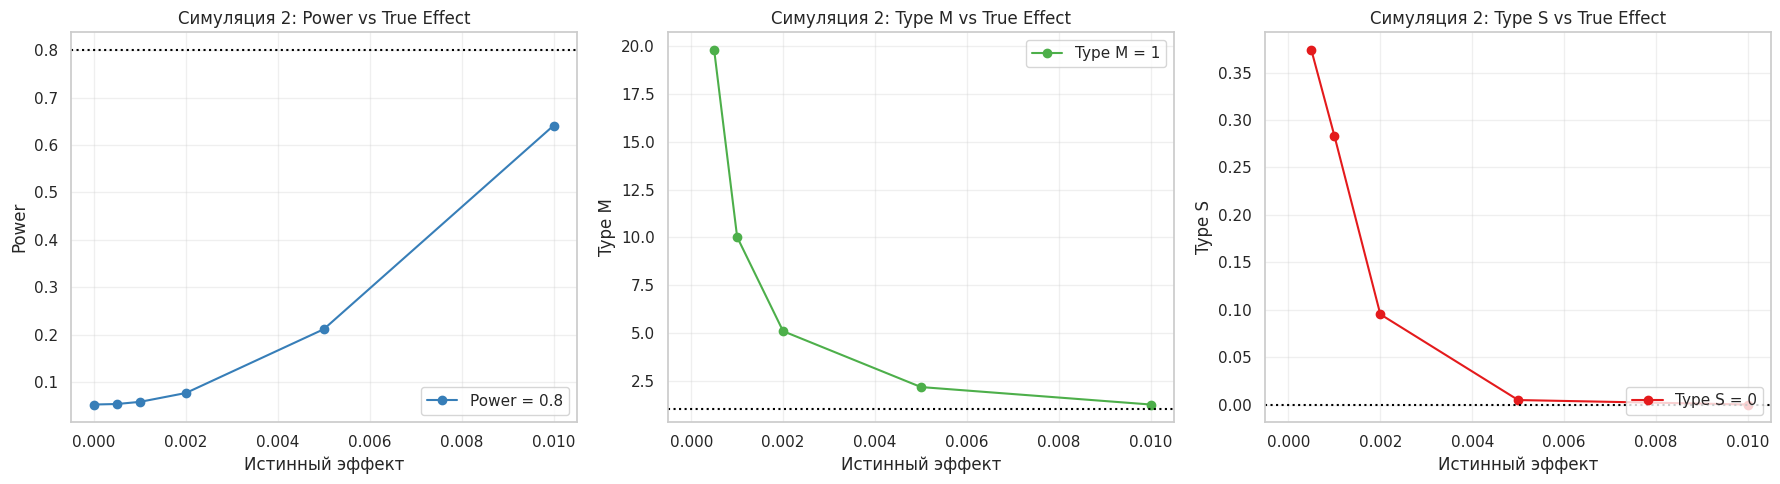

In [18]:
# Общая ширина для всех графиков
fig_width = 18

# Цветовая палитра
colors = {
    "power": "#377eb8",
    "type_m": "#4daf4a",
    "type_s": "#e41a1c"
}

# Создаём фигуру для трёх графиков в один ряд
fig, axes = plt.subplots(1, 3, figsize=(fig_width, 5), sharex=True)

# --- Power vs True Effect ---
axes[0].plot(df_sim2["true_effect"], df_sim2["power"], marker="o", color=colors["power"])
axes[0].axhline(0.8, linestyle=":", color="black")
axes[0].set_title("Симуляция 2: Power vs True Effect")
axes[0].set_xlabel("Истинный эффект")
axes[0].set_ylabel("Power")
axes[0].grid(alpha=0.3)
axes[0].legend(["Power = 0.8"], loc='lower right')

# --- Type M vs True Effect ---
axes[1].plot(df_sim2["true_effect"], df_sim2["type_m"], marker="o", color=colors["type_m"])
axes[1].axhline(1.0, linestyle=":", color="black")
axes[1].set_title("Симуляция 2: Type M vs True Effect")
axes[1].set_xlabel("Истинный эффект")
axes[1].set_ylabel("Type M")
axes[1].grid(alpha=0.3)
axes[1].legend(["Type M = 1"], loc='upper right')

# --- Type S vs True Effect ---
axes[2].plot(df_sim2["true_effect"], df_sim2["type_s"], marker="o", color=colors["type_s"])
axes[2].axhline(0.0, linestyle=":", color="black")
axes[2].set_title("Симуляция 2: Type S vs True Effect")
axes[2].set_xlabel("Истинный эффект")
axes[2].set_ylabel("Type S")
axes[2].grid(alpha=0.3)
axes[2].legend(["Type S = 0"], loc='lower right')

plt.tight_layout()
plt.show()

In [17]:
# =========================
# проверка: что происхоит при true effect = 0
# =========================
df_zero_effect = df_sim2[df_sim2["true_effect"] == 0.0].copy()
df_zero_effect

,true_effect,power,type_s,type_m,significant_count,type_m_stable,note
0,0.0,0.05295,NaN,NaN,1059,True,


Симуляция №2 показывает, что при фиксированном размере выборки качество вывода целиком определяется величиной истинного эффекта относительно шума.

##### **Маленький эффект**
При очень маленьком эффекте, например $\theta = 0.0005$, мощность практически не отличается от уровня значимости ($\text{power} \approx 0.054$ при $\alpha = 0.05$). Это означает, что тест фактически не видит сигнала: значимые результаты возникают почти исключительно за счёт случайного шума, а не из-за реального обнаружения эффекта. В этом режиме **Type M достигает примерно 20**, а **Type S около 0.37**, то есть примерно каждый третий значимый результат имеет неверный знак.

##### **Средний эффект**
По мере роста эффекта ситуация улучшается, но неравномерно. Например, переход от $\theta = 0.002$ к $\theta = 0.005$ даёт резкое улучшение качества вывода: мощность увеличивается примерно с $0.08$ до $0.21$, **Type M падает с $\sim 5.1$ до $\sim 2.2$**, а **Type S — с $\sim 0.095$ до $\sim 0.005$**. Именно в этой зоне небольшое увеличение истинного эффекта даёт наибольший выигрыш в надёжности оценки.

##### **Крупный эффект**

При более крупном эффекте, например $\theta = 0.01$, мощность достигает около $0.64$, **Type M приближается к $1.26$**, а **Type S практически равен нулю**. Это уже режим, в котором значимые результаты достаточно надёжны как по знаку, так и по масштабу эффекта.

\
Главный практический вывод: если команда не знает заранее величину эффекта и он может оказаться очень маленьким, то даже при $n = 10\,000$ на группу значимый результат может быть крайне ненадёжным. В такой ситуации важно не ограничиваться проверкой $p$-value, а явно задавать вопрос: **“в каком диапазоне реалистичных эффектов мы находимся и каков Type M в этой зоне?”**

### Симуляция №3: significance filter и “winner’s curse”

##### **Significance Filter**

Пусть в каждом повторении эксперимента оценка эффекта $\hat{\theta}$ случайно колеблется вокруг истинного $\theta$.

Тогда распределение всех оценок в среднем центрировано около истинного эффекта.  
Но если мы оставляем только те результаты, которые прошли порог значимости, то мы отбираем **не все оценки**, а только **экстремальные хвосты распределения**. Именно этот отбор и создаёт систематическое завышение.


##### **Winner’s curse**

Термин **winner’s curse** пришёл из аукционов. Его смысл в том, что победитель часто “побеждает” именно потому, что сильнее всех переоценил ценность объекта и в итоге переплатил.

В A/B-тестах возникает очень похожая логика. Если провести много одинаковых шумных экспериментов, то статистически значимыми чаще окажутся те, где наблюдённый эффект случайно оказался особенно большим по модулю.  
То есть “побеждает” тот результат, который оказался самым удачным или самым экстремальным, а не обязательно самым близким к истине.

Именно поэтому термин winner’s curse хорошо описывает ситуацию со значимыми результатами в слабых тестах:  
**мы видим не типичный эффект, а эффект, прошедший через отбор в сторону экстремальности.**

In [19]:
# =========================
# симуляция №3
# =========================

p_control = BASE_CONFIG["p_control"]
p_test = BASE_CONFIG["p_test_main"]     # истинный uplift = 0.002
n_per_group = 5_000
alpha = BASE_CONFIG["alpha"]
n_sim = BASE_CONFIG["n_sim_hist"]

sim3 = simulate_ab_binary(
    p_control=p_control,
    p_test=p_test,
    n_per_group=n_per_group,
    n_sim=n_sim,
    alpha=alpha,
    seed=BASE_CONFIG["base_seed"] + 3000,
    min_significant_for_stable_m=BASE_CONFIG["min_significant_for_stable_m"]
)

sim3["significant_effects"] = sim3["effect_hat"][sim3["significant"]]

print("True effect:", sim3["true_effect"])
print("Power:", round(sim3["power"], 4))
print("Type S:", round(sim3["type_s"], 4) if pd.notna(sim3["type_s"]) else np.nan)
print("Type M:", round(sim3["type_m"], 4) if pd.notna(sim3["type_m"]) else np.nan)
print("Significant results count:", sim3["significant_count"])
print("Type M stable?:", sim3["type_m_stable"])

True effect: 0.001999999999999988
Power: 0.0626
Type S: 0.1766
Type M: 7.119
Significant results count: 3132
Type M stable?: True


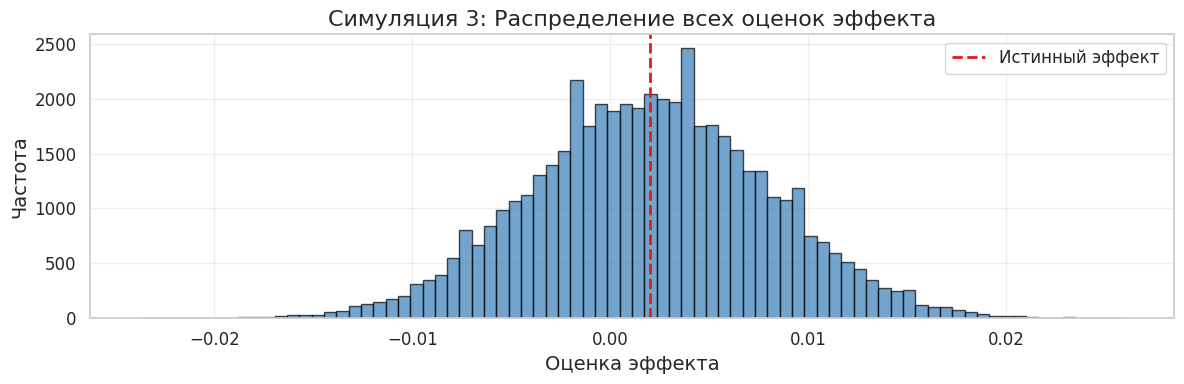

In [25]:
# =========================
# гистограмма всех оценок эффекта
# =========================

plt.figure(figsize=(12, 4))
plt.hist(sim3["effect_hat"], bins=80, color="#377eb8", edgecolor='black', alpha=0.7)

plt.axvline(sim3["true_effect"], linestyle="--", color="#e41a1c", linewidth=2, label="Истинный эффект")

plt.xlabel("Оценка эффекта", fontsize=14)
plt.ylabel("Частота", fontsize=14)
plt.title("Симуляция 3: Распределение всех оценок эффекта", fontsize=16)


plt.legend(fontsize=12)
plt.grid(alpha=0.3)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

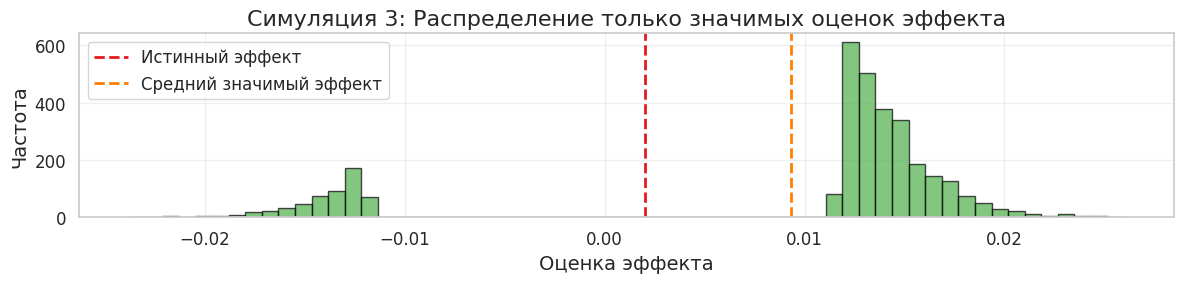

In [27]:
# =========================
# гистограмма только значимых оценок эффекта
# =========================

plt.figure(figsize=(12, 3))
plt.hist(sim3["significant_effects"], bins=60, color="#4daf4a", edgecolor='black', alpha=0.7)

plt.axvline(sim3["true_effect"], linestyle="--", color="#e41a1c", linewidth=2, label="Истинный эффект")
plt.axvline(np.mean(sim3["significant_effects"]), linestyle="--", color="#ff7f00", linewidth=2, label="Средний значимый эффект")

plt.xlabel("Оценка эффекта", fontsize=14)
plt.ylabel("Частота", fontsize=14)
plt.title("Симуляция 3: Распределение только значимых оценок эффекта", fontsize=16)

plt.legend(fontsize=12)
plt.grid(alpha=0.3)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

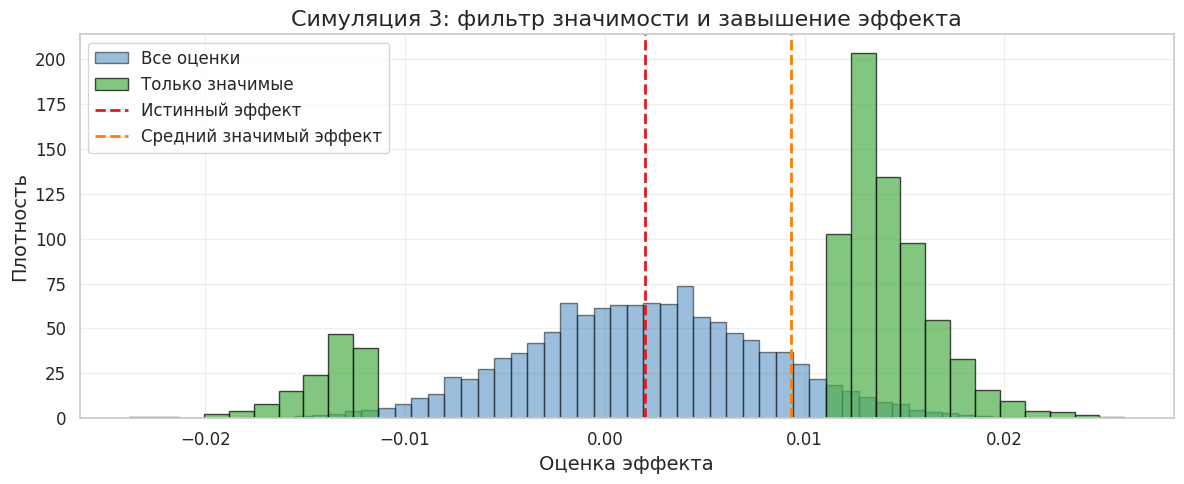

In [28]:
# =========================
# сравнение всех оценок и только значимых
# =========================

plt.figure(figsize=(12, 5))

# Гистограмма всех оценок
plt.hist(sim3["effect_hat"], bins=60, density=True, alpha=0.5, label="Все оценки", color="#377eb8", edgecolor='black')

# Гистограмма только значимых оценок
plt.hist(sim3["significant_effects"], bins=40, density=True, alpha=0.7, label="Только значимые", color="#4daf4a", edgecolor='black')

plt.axvline(sim3["true_effect"], linestyle="--", color="#e41a1c", linewidth=2, label="Истинный эффект")
plt.axvline(np.mean(sim3["significant_effects"]), linestyle="--", color="#ff7f00", linewidth=2, label="Средний значимый эффект")

plt.xlabel("Оценка эффекта", fontsize=14)
plt.ylabel("Плотность", fontsize=14)
plt.title("Симуляция 3: фильтр значимости и завышение эффекта", fontsize=16)


plt.legend(fontsize=12)
plt.grid(alpha=0.3)


plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

In [31]:
# =========================
# числовая иллюстрация WINNER'S CURSE
# =========================

import pandas as pd
from IPython.display import display, HTML

summary_sim3 = pd.DataFrame({
    "Показатель": [
        "Истинный эффект",
        "Средняя оценка по всем симуляциям",
        "Средняя оценка среди значимых",
        "Статистическая мощность (Power)",
        "Вероятность ошибки типа S (Type S)",
        "Оценка завышения эффекта (Type M)",
        "Количество значимых результатов",
        "Стабильность оценки эффекта M"
    ],
    "Значение": [
        sim3["true_effect"],
        np.round(np.mean(sim3["effect_hat"]), 3),
        np.round(np.mean(sim3["significant_effects"]), 3),
        np.round(sim3["power"], 3),
        np.round(sim3["type_s"], 3),
        np.round(sim3["type_m"], 3),
        sim3["significant_count"],
        sim3["type_m_stable"]
    ]
})

summary_sim3_transposed = summary_sim3.set_index("Показатель").T
display(HTML(summary_sim3_transposed.to_html()))

Показатель,Истинный эффект,Средняя оценка по всем симуляциям,Средняя оценка среди значимых,Статистическая мощность (Power),Вероятность ошибки типа S (Type S),Оценка завышения эффекта (Type M),Количество значимых результатов,Стабильность оценки эффекта M
Значение,0.002,0.002,0.009,0.063,0.177,7.119,3132,True


Симуляция №3 наиболее наглядно показывает механизм завышения эффекта — через прямое сравнение двух распределений: всех оценок и только значимых.

**Первый ключевой факт**: оценщик сам по себе несмещён. Среднее по всем $50\,000$ повторениям равно $0.001995$ и практически совпадает с истинным эффектом $\theta = 0.002$. Это важно: проблема не в том, что метод некорректен или формула неверна — в среднем оценка даёт правильный результат.

Проблема возникает после применения фильтра значимости. Из $50\,000$ повторений только $3\,132$ дали значимый результат — это соответствует мощности около $6\%$. То есть мы отбираем лишь небольшую долю экспериментов, причём именно тех, где наблюдённый эффект оказался достаточно большим по модулю.

Среди этих значимых результатов средняя оценка эффекта составляет примерно $0.00933$, что в **4.7 раза больше истинного значения** по правому хвосту и примерно в **7.1 раза больше по модулю** с учётом Type S. Таким образом, мы наблюдаем не типичные реализации эксперимента, а его экстремальные значения.

Это и есть проявление **winner's curse**: значимыми оказываются те эксперименты, в которых шум случайно усилил сигнал. Правый хвост даёт завышенные положительные оценки, а левый — экстремальные отрицательные значения, соответствующие Type S ошибкам.

**Практический вывод:** если команда проводит такой эксперимент один раз и получает значимый uplift порядка $0.009$–$0.013$, то с высокой вероятностью это не реальный эффект фичи, а экстремальная реализация шума. Реальный эффект при этом может быть в несколько раз меньше наблюдаемого.

Именно поэтому статистическая значимость в слабом эксперименте — это не конец анализа, а повод дополнительно оценить **Type M** и задать вопрос **“не является ли наблюдаемый эффект завышенной оценкой из-за фильтра значимости?”**

## 5. Как это использовать в реальном A/B-тесте

Рассмотрим практическую ситуацию.

Команда хочет протестировать новую фичу и ожидает очень небольшой эффект на конверсию.  
Например, исторически подобные изменения давали uplift порядка $0.1 \text{–} 0.3 \text{ п.п.}$

Обычно команда:

- задаёт $\alpha = 0.05$
- выбирает желаемую мощность, например $80\%$
- считает размер выборки под MDE

После этого полезно дополнительно спросить:

1. Если реальный uplift действительно около $0.2$ п.п.,
   каков у нас **Type M**?
2. Если эксперимент всё-таки станет значимым, насколько вероятно, что observed uplift окажется заметно больше реального?
3. Есть ли риск **Type S**, если эффект очень мал и данные шумные?

Таким образом, хороший вывод по A/B-тесту должен отвечать на 5 вопросов:

1. Какой observed effect?
2. Является ли он статистически значимым?
3. Какова мощность теста для правдоподобного эффекта такого масштаба?
4. Каков риск Type S?
5. Насколько велик возможный Type M, то есть завышение эффекта среди значимых результатов?

Только после этого решение “катить / не катить” становится действительно обоснованным.

In [32]:
# =========================
# прикладной бизнесовый блок
# =========================

p_control = 0.10
p_test = 0.102
alpha = 0.05
n_sim = 20000

business_scenarios = {
    "Маленькая выборка": 3_000,
    "Средняя выборка": 15_000,
    "Большая выборка": 80_000
}

rows = []

for scenario_name, n in business_scenarios.items():
    sim = simulate_ab_binary(
        p_control=p_control,
        p_test=p_test,
        n_per_group=n,
        n_sim=n_sim,
        alpha=alpha,
        seed=BASE_CONFIG["base_seed"] + 5000 + n,
        min_significant_for_stable_m=BASE_CONFIG["min_significant_for_stable_m"]
    )

    rows.append({
        "Сценарий": scenario_name,
        "n на группу": n,
        "True effect": sim["true_effect"],
        "Power": sim["power"],
        "Type S": sim["type_s"],
        "Type M": sim["type_m"],
        "Число значимых симуляций": int(sim["significant_count"])
    })

df_business = pd.DataFrame(rows)
df_business

,Сценарий,n на группу,True effect,Power,Type S,Type M,Число значимых симуляций
0,Маленькая выборка,3000,0.002,0.0566,0.231449,9.256331,1132
1,Средняя выборка,15000,0.002,0.0909,0.067107,4.222204,1818
2,Большая выборка,80000,0.002,0.2656,0.001883,1.941683,5312


## 6. Примеры из статьи Gelman & Carlin

Авторы иллюстрируют идею Design Analysis на двух реальных опубликованных исследованиях.  
Оба кейса показывают одно и то же: **статистическая значимость сама по себе не говорит о том, что результат надёжен**.

### Кейс 1. Привлекательность родителей и пол ребёнка (Kanazawa, 2007)

Исследователь проанализировал данные ~3 000 респондентов и обнаружил, что среди детей
родителей из категории «самые привлекательные» 56% составляют девочки, тогда как
в остальных группах — 48%. Разница в 8 п.п. оказалась статистически значимой ($p = 0.015$).

Gelman и Carlin применяют к этому результату Design Analysis, задавая ключевой вопрос: **каков реалистичный истинный эффект?**

По данным демографической литературы, вариация доли рождений девочек между группами
составляет менее 0.3–0.2 п.п. Авторы рассматривают три сценария истинного эффекта:
$\theta \in [0.1\%, 0.3\%, 1.0\%]$.

Из статьи: стандартная ошибка оценки $SE = 3.3\%$.

Ниже аналитически воспроизведены расчёты и есть сравнение с результатами из статьи.

> **Уточнение**: Gelman & Carlin использовали аналитическую формулу с нормальным
> приближением через функцию `retrodesign()` на R. А у меня в коде реализован её аналог,
> поэтому небольшое расхождение в числах возможно — за счёт симуляционной части
> при вычислении Type M.

In [33]:
# =========================
# КЕЙС 1: привлекательность и пол ребенка
# =========================

from scipy.stats import norm as sp_norm

def retrodesign_analytic(true_effect, se, alpha=0.05):
    """
    Аналитический расчёт Power, Type S и Type M
    по методу Gelman & Carlin (2014).

    Параметры:
    true_effect : истинный эффект D
    se          : стандартная ошибка оценки s
    alpha       : уровень значимости

    Формулы из статьи (нормальное приближение):
    power  = P(|Z| > z_alpha) при Z ~ N(D/s, 1)
    type_s = P(Z < -z_alpha) / power
    type_m = E(|estimate| | significant) / |D|  — через симуляцию
    """
    z = sp_norm.ppf(1 - alpha / 2)
    D = true_effect
    s = se

    p_hi = 1 - sp_norm.cdf(z - D / s)
    p_lo = sp_norm.cdf(-z - D / s)
    power = p_hi + p_lo

    if power < 1e-10:
        return {"power": power, "type_s": float("nan"), "type_m": float("nan")}

    type_s = p_lo / power

    # type_m через симуляцию усечённого нормального
    rng = np.random.default_rng(42)
    n_sim = 100_000
    estimates = D + s * rng.standard_normal(n_sim)
    significant = np.abs(estimates) > z * s
    if significant.sum() == 0:
        type_m = float("nan")
    else:
        type_m = np.mean(np.abs(estimates[significant])) / abs(D)

    return {"power": power, "type_s": type_s, "type_m": type_m}


# Параметры кейса 1 из статьи
# SE = 3.3 п.п. = 0.033
se_k = 0.033

scenarios_k = {
    "θ = 0.1 п.п.": 0.001,
    "θ = 0.3 п.п.": 0.003,
    "θ = 1.0 п.п.": 0.010,
}

rows_k = []
for label, effect in scenarios_k.items():
    res = retrodesign_analytic(true_effect=effect, se=se_k)
    rows_k.append({
        "Сценарий": label,
        "Истинный эффект": effect,
        "Power": round(res["power"], 3),
        "Type S": round(res["type_s"], 3),
        "Type M": round(res["type_m"], 1),
    })

df_k = pd.DataFrame(rows_k)

print("Кейс 1: Привлекательность и пол ребёнка")
print("Результаты из статьи Gelman & Carlin для сравнения:")
print("  θ=0.1%: power≈2.7%,  Type S≈46%, Type M≈77")
print("  θ=0.3%: power≈3.0%,  Type S≈40%, Type M≈25")
print("  θ=1.0%: power≈6.0%,  Type S≈19%, Type M≈8")
print()
df_k

Кейс 1: Привлекательность и пол ребёнка
Результаты из статьи Gelman & Carlin для сравнения:
  θ=0.1%: power≈2.7%,  Type S≈46%, Type M≈77
  θ=0.3%: power≈3.0%,  Type S≈40%, Type M≈25
  θ=1.0%: power≈6.0%,  Type S≈19%, Type M≈8



,Сценарий,Истинный эффект,Power,Type S,Type M
0,θ = 0.1 п.п.,0.001,0.050,0.465,77.4
1,θ = 0.3 п.п.,0.003,0.051,0.395,25.8
2,θ = 1.0 п.п.,0.010,0.061,0.195,7.8


> **Уточнение по power**: Gelman & Carlin раздельно рассматривают
> вероятность получить значимый результат в **правильном** и
> **неправильном** направлении. В моей реализации power считается как
> **суммарная двусторонняя вероятность значимости**, поэтому для очень малых
> эффектов возможны расхождения в числах. Это не меняет главный вывод:
> оценки **Type S** и **Type M** воспроизводят ту же картину и показывают,
> что значимые результаты в слабом эксперименте могут иметь неверный знак
> и сильно завышать истинный эффект.

### Кейс 2. Менструальный цикл и политические предпочтения (Durante et al., 2013)

Исследование сообщало о разнице в 17 п.п. в предпочтениях при голосовании между женщинами
в разных фазах менструального цикла ($p = 0.035$).

Из статьи: $SE = 8.1\%$, то есть исследование было **очень шумным** — стандартная ошибка
в 8 раз превышает правдоподобный истинный эффект.

Gelman и Carlin оценивают реалистичный эффект: по данным о стабильности политических
предпочтений (колебания поддержки кандидатов в течение всей кампании составляли не более 7 п.п.),
правдоподобный максимум — около **2 п.п.**

Результаты из статьи при $\theta = 2\%$ и $SE = 8.1\%$:

| Метрика | Значение из статьи |
|---|---|
| Power | 6% |
| Type S | 24% |
| Type M | 9.7 |

Наблюдённый эффект в 17 п.п. при реальном в ~2 п.п. — типичный пример winner's curse:
значимым оказался не типичный результат, а экстремальная реализация шума.

Ниже воспроизводим этот кейс аналитически, используя тот же метод, что и авторы

In [34]:
# =========================
# КЕЙС 2: менструальный цикл и политические предпочтения
# =========================

# SE = 8.1 п.п. = 0.081
se_d = 0.081

scenarios_d = {
    "θ = 2 п.п. (правдоподобный)": 0.02,
    "θ = 5 п.п. (оптимистичный)":  0.05,
    "θ = 17 п.п. (наблюдённый)":   0.17,
}

rows_d = []
for label, effect in scenarios_d.items():
    res = retrodesign_analytic(true_effect=effect, se=se_d)
    rows_d.append({
        "Сценарий": label,
        "Истинный эффект": effect,
        "Power": round(res["power"], 3),
        "Type S": round(res["type_s"], 3),
        "Type M": round(res["type_m"], 1),
    })

df_d = pd.DataFrame(rows_d)

print("Кейс 2: Менструальный цикл и политические предпочтения")
print("Результат из статьи при θ=2%: power≈6%, Type S≈24%, Type M≈9.7")
print()
df_d

Кейс 2: Менструальный цикл и политические предпочтения
Результат из статьи при θ=2%: power≈6%, Type S≈24%, Type M≈9.7



,Сценарий,Истинный эффект,Power,Type S,Type M
0,θ = 2 п.п. (правдоподобный),0.02,0.057,0.240,9.6
1,θ = 5 п.п. (оптимистичный),0.05,0.095,0.053,3.9
2,θ = 17 п.п. (наблюдённый),0.17,0.555,0.000,1.3


### Что показывают оба кейса

В обоих исследованиях авторы получили статистически значимые результаты с большими наблюдёнными эффектами — 8 п.п. и 17 п.п. соответственно.

Но Design Analysis показывает: при правдоподобных истинных эффектах оба дизайна были слишком слабыми, чтобы делать надёжные выводы.

Это не означает, что исходные результаты заведомо неверны. Это означает, что **такие дизайны не позволяли отличить реальный эффект от шума** — ни по знаку, ни по масштабу.

Именно это и делает Design Analysis полезным инструментом: он позволяет честно оценить, что именно можно узнать из данного эксперимента, ещё до того как результат будет интерпретирован как факт.

Для A/B-тестов вывод тот же: если дизайн слабый относительно правдоподобного эффекта, значимый результат — это не конец анализа, а повод задать дополнительные вопросы.

## 7. Выводы

Основные результаты доклада

1. **Мощность — важная, но не исчерпывающая характеристика эксперимента.**  
   Она показывает вероятность обнаружить эффект, но не говорит, насколько можно доверять знаку и размеру значимого результата.

2. **Type S error** показывает риск перепутать направление эффекта.  
   Для A/B-тестов это особенно опасно, потому что можно принять продуктовое решение в неправильную сторону.

3. **Type M error** показывает, насколько сильно значимый результат может преувеличивать реальный uplift.  
   С практической точки зрения это одна из самых важных проблем слабых тестов.

4. **Низкая мощность опасна не только пропуском эффекта, но и плохим качеством “победных” результатов.**  
   Именно это делает Type S и Type M необходимыми для интерпретации A/B-тестов.

5. **Design Analysis** — более полезный фреймворк, чем изолированный Power Analysis.  
   Он позволяет оценивать не только вероятность значимости, но и риски ошибочного знака и преувеличенного масштаба эффекта.

## Что делать с проблемой на практике?

Design Analysis показывает проблему. Но что с ней делать на практике?

Gelman и Carlin не предлагают одного универсального решения — скорее набор принципов. Ниже — основные подходы, которые используются в практике экспериментов.


### 1. Самый крутой и надёжный способ — репликация

  Если результат A/B-теста важен для бизнес-решения, лучший способ проверить его надёжность — **повторить эксперимент**.

  Почему это работает:

  - winner's curse возникает при единственном прогоне через фильтр значимости;
  - в независимой репликации тот же артефакт воспроизведётся только если эффект реальный;
  - если в репликации наблюдённый эффект заметно меньше исходного — это сигнал, что исходный результат был завышен.

  На практике репликацию можно делать как отдельный тест на другом периоде или другом сегменте пользователей.


### 2. Байесовское сжатие (shrinkage)

Байесовский подход позволяет скорректировать оценку эффекта с учётом априорных знаний о правдоподобном диапазоне эффектов.

**Идея:** если мы знаем, что большинство фич дают эффект в диапазоне 0–0.5 п.п., то экстремальная значимая оценка в 1.5 п.п. должна быть «притянута» ближе к центру распределения.

Это называется **shrinkage** или **regularization**:

$$
\hat{\theta}_{\text{adjusted}} = \lambda \cdot \hat{\theta}_{\text{observed}} + (1 - \lambda) \cdot \mu_{\text{prior}}
$$

где $\lambda$ определяется соотношением точности данных и надёжности априорного знания.

Байесовская поправка особенно полезна в компаниях, которые накопили историю A/B-тестов: исторические эффекты можно использовать как информированный prior.


### 3. Планирование через Design Analysis

Gelman и Carlin предлагают делать Design Analysis **до** запуска теста, а не только после.

Это означает:

1. Оценить правдоподобный диапазон эффектов на основе истории похожих тестов или доменной экспертизы.
2. Для каждого сценария посчитать не только Power, но и ожидаемые Type M и Type S.
3. Если Type M высокий уже при реалистичном эффекте — честно признать: «этот дизайн не позволяет надёжно оценить масштаб эффекта».
4. Либо увеличить выборку, либо скорректировать интерпретацию результата заранее.

Из статьи Gelman & Carlin можно вывести простое ориентировочное правило:

- при power > 0.5 — Type M уже умеренный, завышение меньше ~2x;
- при power < 0.1 — Type S становится заметным (>5%), знаку нельзя доверять;
- при power ~0.8 — Type M ≈ 1.12, Type S практически нулевой.

То есть стандартный ориентир power = 80% — это не просто конвенция, а порог, за которым значимые результаты становятся реально надёжными по знаку и масштабу.

### Чего делать не стоит

Gelman особо предупреждает об одной распространённой ошибке:

**Не нужно** после получения значимого результата подставлять наблюдённый эффект в ретроспективный Power Analysis и радоваться этой «высокой мощности».

Это создаёт ложное ощущение надёжности: наблюдённый эффект уже прошёл через фильтр значимости и смещён вверх. Подставляя его обратно, мы просто подтверждаем сами себя.

## Источники

### Основные источники

1. Gelman, A., Carlin, J.  
   *Beyond Power Calculations: Assessing Type S (Sign) and Type M (Magnitude) Errors*  
   [PDF](https://sites.stat.columbia.edu/gelman/research/published/retropower_final.pdf)

2. Антон Москвин  
   *Когда недостаточно ошибок I/II рода и нужно уточнить результат A/B теста*  
   [Habr](https://habr.com/ru/articles/996474/)

### Дополнительные источники

3. UVA StatLab  
   *Assessing Type S and Type M Errors*  
   [Article](https://library.virginia.edu/data/articles/assessing-type-s-and-type-m-errors)

4. Andrew Gelman  
   *More on my paper with John Carlin on Type M and Type S errors*  
   [Blog post](https://statmodeling.stat.columbia.edu/2016/11/13/more-on-my-paper-with-john-carlin-on-type-m-and-type-s-errors/)

5. Jaksic, C., Perneger, T., Combescure, C.  
   *Statistically significant results from low-power analyses: A comedy of errors*  
   [ScienceDirect](https://www.sciencedirect.com/science/article/pii/S2590113326000088)

6. CRAN package `retrodesign`  
   [Package page](https://cran.r-project.org/package=retrodesign)